# Week 10 tutorial · Deep learning and CNNs

Open this notebook in Jupyter, VS Code or Google Colab and select **Run All**.
The setup cell installs missing packages in the active Python kernel, and Keras downloads
CIFAR-10 on the first run (about 170 MB). The baseline trains for 15 epochs.
The ResNet50 challenge defaults to a short comparison. The setup cell also offers
a full 10-epoch comparison and a setting to skip the challenge.

[Course worksheet](6COSC020W_TutorialCNN.pdf) · [CIFAR-10 documentation](https://keras.io/api/datasets/cifar10/)

The saved CPU run took about four minutes with the dataset cached.

In [1]:
import importlib
import importlib.util
import subprocess
import sys

# Install missing packages using the notebook kernel's Python.
packages = {
    "tensorflow": "tensorflow==2.21.0",
    "matplotlib": "matplotlib",
}
missing = [
    requirement for module, requirement in packages.items()
    if importlib.util.find_spec(module) is None
]
if missing:
    print("Installing " + ", ".join(missing) + " in the active kernel...", flush=True)
    subprocess.run([sys.executable, "-m", "pip", "install", *missing], check=True)
    importlib.invalidate_caches()

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

get_ipython().run_line_magic("matplotlib", "inline")

SEED = 123
BASELINE_EPOCHS = 15
BATCH_SIZE = 128
RESNET_CHALLENGE = "quick"  # "quick", "full", or "skip"
tf.keras.utils.set_random_seed(SEED)

devices = tf.config.list_physical_devices("GPU")
print(f"TensorFlow {tf.__version__} | Device: {'GPU' if devices else 'CPU'}")

TensorFlow 2.21.0 | Device: CPU


## Worksheet 1 · Key terms

| Term | Explanation |
| --- | --- |
| Deep learning | A form of machine learning that uses many successive layers to learn representations of data. |
| Classification | Predicting a category for an input, such as whether a photo contains a cat or a dog. |
| Features | Patterns or measurements that help make a prediction. An image feature can be an edge, a texture or a shape. |
| Filters | Small arrays of learned weights that respond to particular patterns as they slide across an image or feature map. |
| Convolution | Sliding a filter over the input and summing elementwise products at each position to build a feature map. |
| CNN | A convolutional neural network. It reuses a filter at many positions and can combine simple patterns into more complex ones in later layers. |
| Convolutional layer | A layer that applies several filters to the input and produces one output feature map per filter. |
| Pooling layer | A layer that summarises each local patch, for example by taking its maximum or mean, to reduce the spatial dimensions. |
| ReLU | The rectified linear unit, defined by $f(x)=\max(0,x)$. It replaces negative values with zero and lets positive values pass through. |
| Computer vision | The field that uses computers to interpret visual data, for example by classifying images or locating objects in video. |

## Worksheet 2 · Calculate a convolution

The worksheet uses a $3\times3$ kernel, stride 1 and no padding. A $5\times5$
image therefore gives a $3\times3$ output. In the top-left patch, the kernel selects
the four corners and the centre, so the first value is $1+1+0+1+1=4$.

In [2]:
image = np.array([
    [1, 1, 1, 0, 0],
    [0, 1, 1, 1, 0],
    [0, 0, 1, 1, 1],
    [0, 0, 1, 1, 0],
    [0, 1, 1, 0, 0],
])
kernel = np.array([
    [1, 0, 1],
    [0, 1, 0],
    [1, 0, 1],
])

# With stride 1, shift the window one column or row at a time.
output_height = image.shape[0] - kernel.shape[0] + 1
output_width = image.shape[1] - kernel.shape[1] + 1
convolved = np.empty((output_height, output_width), dtype=int)
for row in range(output_height):
    for col in range(output_width):
        patch = image[row:row + kernel.shape[0], col:col + kernel.shape[1]]
        convolved[row, col] = np.sum(patch * kernel)

print("Convolution result")
print(convolved)

Convolution result
[[4 3 4]
 [2 4 3]
 [2 3 4]]


## Worksheet 3 · Calculate max and average pooling

A $2\times2$ window with stride 2 gives four non-overlapping windows in this
$4\times4$ feature map. The top-left window contains 29, 15, 0 and 100.
Its max is **100** and its mean is **36**.

In [3]:
feature_map = np.array([
    [29, 15, 28, 184],
    [0, 100, 70, 38],
    [12, 12, 7, 2],
    [12, 12, 45, 6],
])
windows = np.lib.stride_tricks.sliding_window_view(feature_map, (2, 2))
# The window helper starts at every pixel. Take every second start for stride 2.
windows = windows[::2, ::2]

# Reduce the two axes inside each window and keep the window's row and column.
print("Max pooling result")
print(windows.max(axis=(-2, -1)))
print("\nAverage pooling result")
print(windows.mean(axis=(-2, -1)))

Max pooling result
[[100 184]
 [ 12  45]]

Average pooling result
[[36. 80.]
 [12. 15.]]


## Practical 1–4 · Load and explore CIFAR-10

CIFAR-10 provides 50,000 training images and 10,000 images in its official test
split. Every image is $32\times32$ pixels with three colour channels.
Following the supplied notebook, we use the official test split as validation
during training and for the metrics below. An independent final evaluation would
require a separate test set held back from model selection.

In [4]:
(train_images, train_labels), (validation_images, validation_labels) = (
    tf.keras.datasets.cifar10.load_data()
)
# Each image has one class ID. Flatten labels from (n, 1) to (n,).
train_labels = train_labels.ravel()
validation_labels = validation_labels.ravel()
class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck",
]
input_shape = train_images.shape[1:]

print(f"Training images: {len(train_images):,}")
print(f"Validation images: {len(validation_images):,}")
print(f"Image shape (height, width, channels): {input_shape}")

Training images: 50,000
Validation images: 10,000
Image shape (height, width, channels): (32, 32, 3)


### Question 1 · Is the dataset balanced?

**Answer.** Yes. Each class has **5,000 training images** and **1,000 validation images**.

In [5]:
# Count the number of times each integer label appears in each split.
train_counts = np.bincount(train_labels, minlength=len(class_names))
validation_counts = np.bincount(validation_labels, minlength=len(class_names))
print(f"{'Class':<12}{'Train':>9}{'Validation':>13}")
for name, train_count, val_count in zip(class_names, train_counts, validation_counts):
    print(f"{name:<12}{train_count:>9,}{val_count:>13,}")

Class           Train   Validation
airplane        5,000        1,000
automobile      5,000        1,000
bird            5,000        1,000
cat             5,000        1,000
deer            5,000        1,000
dog             5,000        1,000
frog            5,000        1,000
horse           5,000        1,000
ship            5,000        1,000
truck           5,000        1,000


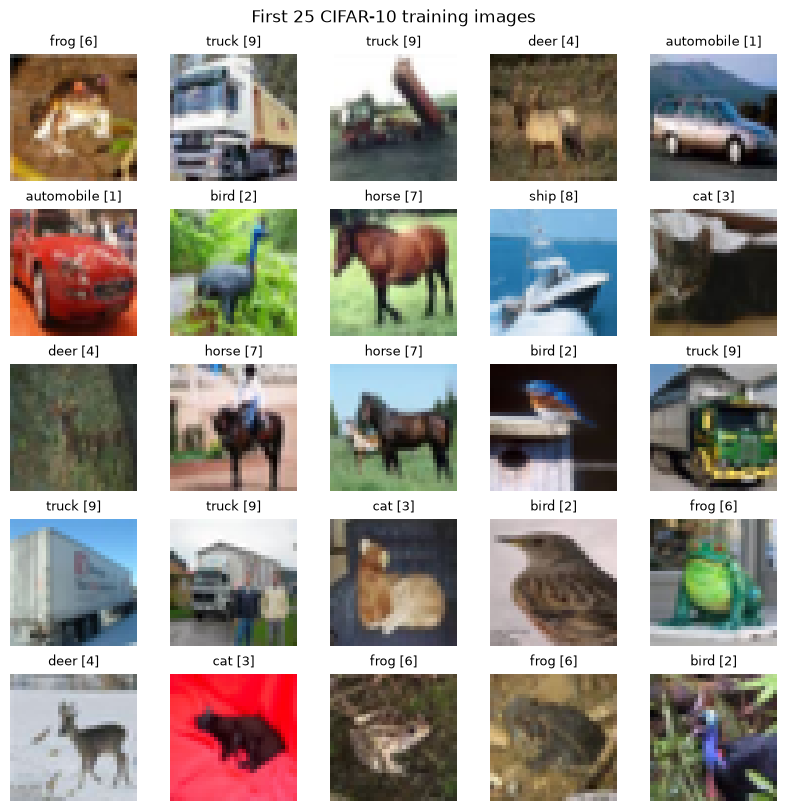

In [6]:
fig, axes = plt.subplots(5, 5, figsize=(8, 8), layout="constrained")
fig.suptitle("First 25 CIFAR-10 training images")
for index, ax in enumerate(axes.flat):
    label = train_labels[index]
    ax.imshow(train_images[index])
    ax.set_title(f"{class_names[label]} [{label}]", fontsize=9)
    ax.axis("off")
plt.show()

## Practical 5–6 · Build and compile the CNN

The three convolutional layers learn 16, 32 and 64 feature maps. Max pooling keeps
the strongest activation in each window, while average pooling keeps its mean.
The dense layer returns ten raw scores called *logits*. The labels are integer
class IDs, so we use sparse categorical cross-entropy with
`from_logits=True`. Adam updates the filter weights, dense weights and biases.

In [7]:
def build_cnn():
    # Keep the dataset in compact uint8 form. Rescale each batch to [0, 1].
    model = tf.keras.Sequential([
        tf.keras.Input(shape=input_shape, dtype="uint8"),
        tf.keras.layers.Rescaling(1.0 / 255),
        tf.keras.layers.Conv2D(16, 3, activation="relu", name="first_conv"),
        tf.keras.layers.MaxPooling2D(pool_size=2, strides=2),
        tf.keras.layers.Conv2D(32, 3, activation="relu"),
        tf.keras.layers.MaxPooling2D(pool_size=2, strides=2),
        tf.keras.layers.Conv2D(64, 3, activation="relu"),
        tf.keras.layers.AveragePooling2D(pool_size=2, strides=2),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(len(class_names), name="class_logits"),
    ], name="tutorial_cnn")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=["accuracy"],
    )
    return model

model = build_cnn()
model.summary()

Model: "tutorial_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ first_conv (Conv2D)             │ (None, 30, 30, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 13, 13, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 4, 4, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 2, 2, 64)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_logits (Dense)            │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,154 (102.16 KB)

 Trainable params: 26,154 (102.16 KB)

 Non-trainable params: 0 (0.00 B)

### Question 2 · How many trainable parameters are in the first convolutional layer?

**Answer.** **448**. Each of the 16 filters has $3\times3\times3=27$ weights
(a $3\times3$ kernel across three input channels) and one bias.
That gives $16\times(27+1)=448$.

### Question 3 · How many trainable parameters do the pooling layers have, and why?

**Answer.** **Zero**. Each pooling layer applies a fixed maximum or mean within
every window, independently for each channel. There are no weights or biases to learn.

## Practical 7–8 · Train, evaluate and plot learning curves

An epoch is one pass through the training set. Keras computes validation metrics
after each epoch using the validation images. A growing gap between training and
validation accuracy, or validation loss rising while training loss falls, can
indicate overfitting.

In [8]:
history = model.fit(
    train_images,
    train_labels,
    validation_data=(validation_images, validation_labels),
    epochs=BASELINE_EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=2,
)

Epoch 1/15
391/391 - 9s - 24ms/step - accuracy: 0.3512 - loss: 1.7787 - val_accuracy: 0.4414 - val_loss: 1.5404
Epoch 2/15
391/391 - 8s - 20ms/step - accuracy: 0.4701 - loss: 1.4757 - val_accuracy: 0.5045 - val_loss: 1.3871
Epoch 3/15
391/391 - 7s - 18ms/step - accuracy: 0.5164 - loss: 1.3565 - val_accuracy: 0.5339 - val_loss: 1.3207
Epoch 4/15
391/391 - 8s - 20ms/step - accuracy: 0.5460 - loss: 1.2801 - val_accuracy: 0.5582 - val_loss: 1.2497
Epoch 5/15
391/391 - 7s - 18ms/step - accuracy: 0.5685 - loss: 1.2209 - val_accuracy: 0.5737 - val_loss: 1.1966
Epoch 6/15
391/391 - 7s - 18ms/step - accuracy: 0.5887 - loss: 1.1724 - val_accuracy: 0.5926 - val_loss: 1.1596
Epoch 7/15
391/391 - 7s - 18ms/step - accuracy: 0.6038 - loss: 1.1325 - val_accuracy: 0.5998 - val_loss: 1.1329
Epoch 8/15
391/391 - 9s - 22ms/step - accuracy: 0.6173 - loss: 1.0995 - val_accuracy: 0.6109 - val_loss: 1.1087
Epoch 9/15
391/391 - 8s - 21ms/step - accuracy: 0.6294 - loss: 1.0709 - val_accuracy: 0.6200 - val_loss:

Validation accuracy: 66.05%
Validation loss: 0.9808


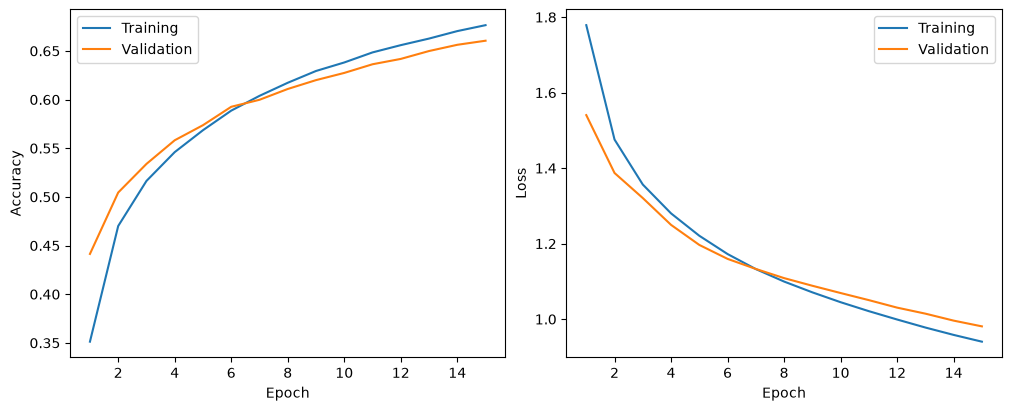

In [9]:
validation_loss, validation_accuracy = model.evaluate(
    validation_images, validation_labels, batch_size=BATCH_SIZE, verbose=0
)
print(f"Validation accuracy: {validation_accuracy:.2%}")
print(f"Validation loss: {validation_loss:.4f}")

# Keras numbers epochs from 1 in the training log, so use the same axis here.
epoch_numbers = np.arange(1, len(history.history["loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
for ax, metric, label in zip(axes, ("accuracy", "loss"), ("Accuracy", "Loss")):
    ax.plot(epoch_numbers, history.history[metric], label="Training")
    ax.plot(epoch_numbers, history.history[f"val_{metric}"], label="Validation")
    ax.set(xlabel="Epoch", ylabel=label)
    ax.legend()
plt.show()

## Practical 9–10 · Convert logits to probabilities and get predicted classes

Softmax converts the ten logits for each image to probabilities that sum to one.
`argmax(axis=1)` returns the index of the largest probability in each image's row.
That index is the predicted class ID.

In [10]:
logits = model.predict(validation_images, batch_size=BATCH_SIZE, verbose=0)
probabilities = tf.nn.softmax(logits, axis=1).numpy()
predictions = np.argmax(probabilities, axis=1)

print(f"Probability array shape: {probabilities.shape}")
print(f"Prediction array shape: {predictions.shape}")
print("\nFirst image's probabilities")
for label, probability in zip(class_names, probabilities[0]):
    print(f"{label:<12} {probability:>7.2%}")
print(f"\nFirst five predictions: {[class_names[i] for i in predictions[:5]]}")
print(f"First five actual labels: {[class_names[i] for i in validation_labels[:5]]}")

Probability array shape: (10000, 10)
Prediction array shape: (10000,)

First image's probabilities
airplane       1.64%
automobile     0.01%
bird           4.28%
cat           70.91%
deer           0.35%
dog           14.91%
frog           6.68%
horse          0.11%
ship           0.89%
truck          0.22%

First five predictions: ['cat', 'ship', 'ship', 'airplane', 'deer']
First five actual labels: ['cat', 'ship', 'ship', 'airplane', 'frog']


## Practical 11 · Read the confusion matrix

Rows are actual labels and columns are predicted labels. The diagonal contains
correct predictions. Every other cell counts errors of a specific type.

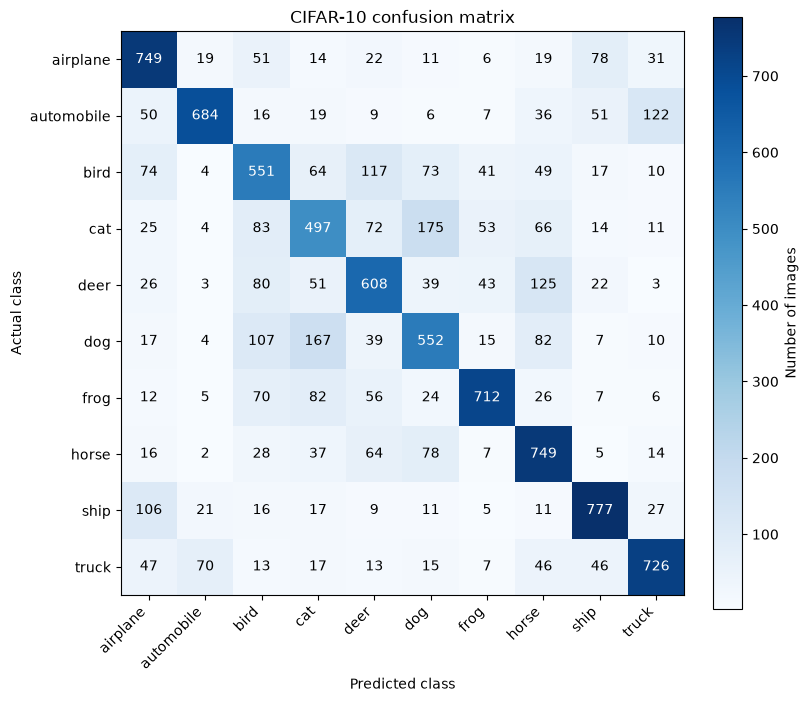

In [11]:
confusion = tf.math.confusion_matrix(
    validation_labels, predictions, num_classes=len(class_names)
).numpy()

fig, ax = plt.subplots(figsize=(8, 7), layout="constrained")
heatmap = ax.imshow(confusion, cmap="Blues")
fig.colorbar(heatmap, ax=ax, label="Number of images")
ax.set(
    title="CIFAR-10 confusion matrix",
    xlabel="Predicted class",
    ylabel="Actual class",
    yticks=range(len(class_names)),
    yticklabels=class_names,
)
ax.set_xticks(range(len(class_names)), labels=class_names, rotation=45, ha="right")
for actual, predicted in np.ndindex(confusion.shape):
    count = confusion[actual, predicted]
    color = "white" if count > confusion.max() / 2 else "black"
    ax.text(predicted, actual, count, ha="center", va="center", color=color)
plt.show()

### Questions 4–6 · Interpret the errors

- **Question 4. How many airplanes were classified correctly?** Read the airplane row
  and airplane column.
- **Question 5. How many cats were classified as frogs?** Read the cat row and frog column.
- **Question 6. Which two actual classes had the most errors, and why might that happen?**
  Subtract the diagonal from each row total and rank the results. Comparing error counts
  is fair here because every class has the same number of validation images.

The code prints the answers for the current run and shows examples for the two classes
with the most errors. At $32\times32$ pixels, fine details can be hard to distinguish.
The CNN also reduces the final feature maps to $1\times1$, so the classifier
has limited spatial detail for separating classes with similar shapes or textures.
The examples illustrate possible causes of errors.

**Saved run.** The CNN correctly classified **749 airplanes** and predicted
**53 cats as frogs**. It made the most mistakes on **cats (503)** and **birds (449)**.
Cats were most often mistaken for dogs (175 images), and birds for deer (117 images).
Several bird examples below have long legs or green outdoor backgrounds. In the cat
examples, low resolution makes facial features and body outlines hard to distinguish.


Q4. Correctly predicted airplanes: 749
Q5. Cats predicted as frogs: 53
Q6. Actual classes with the most wrong predictions
  Cat: 503 errors out of 1000. Most often predicted as dog (175 images).
  Bird: 449 errors out of 1000. Most often predicted as deer (117 images).


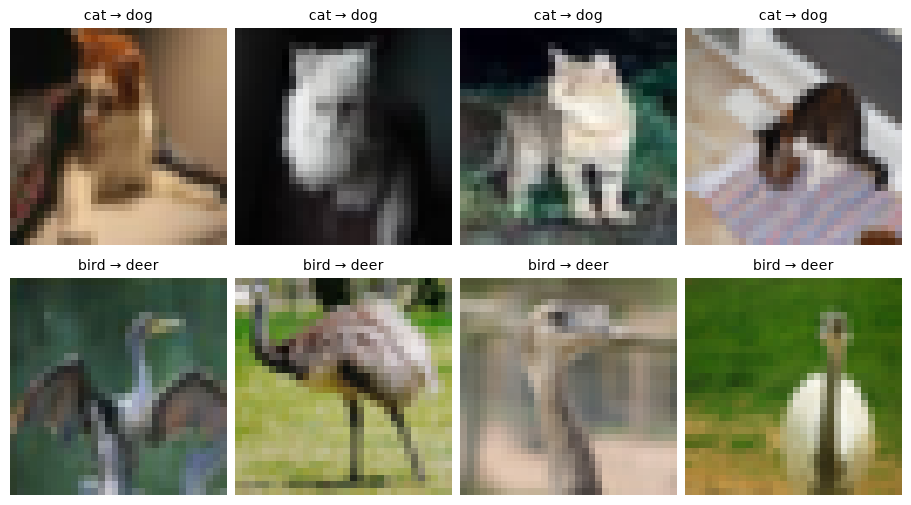

In [12]:
airplane = class_names.index("airplane")
cat = class_names.index("cat")
frog = class_names.index("frog")
print(f"Q4. Correctly predicted airplanes: {confusion[airplane, airplane]:,}")
print(f"Q5. Cats predicted as frogs: {confusion[cat, frog]:,}")

# Each row's sum is the number of actual examples in that class.
wrong_counts = confusion.sum(axis=1) - confusion.diagonal()
top_two = np.argsort(-wrong_counts, kind="stable")[:2]
print("Q6. Actual classes with the most wrong predictions")
fig, axes = plt.subplots(2, 4, figsize=(9, 5), layout="constrained")
for actual, row_axes in zip(top_two, axes):
    wrong_columns = confusion[actual].copy()
    wrong_columns[actual] = 0
    most_common_error = int(wrong_columns.argmax())
    print(
        f"  {class_names[actual].capitalize()}: {wrong_counts[actual]} errors out of "
        f"{confusion[actual].sum()}. Most often predicted as "
        f"{class_names[most_common_error]} ({wrong_columns[most_common_error]} images)."
    )

    # Show up to four examples of the most frequent error for this actual class.
    example_indices = np.flatnonzero(
        (validation_labels == actual) & (predictions == most_common_error)
    )[:len(row_axes)]
    for ax in row_axes:
        ax.axis("off")
    for ax, index in zip(row_axes, example_indices):
        ax.imshow(validation_images[index])
        ax.set_title(f"{class_names[actual]} → {class_names[predictions[index]]}", fontsize=10)
plt.show()

## Optional challenge · Compare with ResNet50

ResNet50 uses shortcut connections that add an earlier activation to the output of
a block. We initialise the network from scratch and attach a classification head.
Global average pooling produces one number per feature map. A dense layer converts
those numbers into ten class logits. [Keras ResNet50 documentation](https://keras.io/api/applications/resnet/resnet_models/)

The **quick** mode trains both models for three epochs on the same 2,000 training
images and validates on the same 1,000 images, sampled equally across classes.
Read this as a short comparison on those splits. Set `RESNET_CHALLENGE = "full"`
in the setup cell for 10 epochs on the full splits. Full ResNet50 training can take
substantially longer on a CPU.

In [13]:
def balanced_sample(labels, examples_per_class, random_generator):
    # Sample the same number from each class, then mix the selected classes.
    selected = np.concatenate([
        random_generator.choice(np.flatnonzero(labels == label), examples_per_class, replace=False)
        for label in range(len(class_names))
    ])
    return random_generator.permutation(selected)

def build_resnet():
    # include_top=False gives feature maps, so add a ten-class head.
    backbone = tf.keras.applications.ResNet50(
        include_top=False, weights=None, input_shape=input_shape
    )
    return tf.keras.Sequential([
        tf.keras.Input(shape=input_shape, dtype="uint8"),
        tf.keras.layers.Rescaling(1.0 / 255),
        backbone,
        tf.keras.layers.GlobalAveragePooling2D(),
        tf.keras.layers.Dense(len(class_names)),
    ], name="cifar10_resnet50")

if RESNET_CHALLENGE in ("quick", "full"):
    if RESNET_CHALLENGE == "quick":
        rng = np.random.default_rng(SEED)
        train_indices = balanced_sample(train_labels, 200, rng)
        val_indices = balanced_sample(validation_labels, 100, rng)
        challenge_train = train_images[train_indices], train_labels[train_indices]
        challenge_val = validation_images[val_indices], validation_labels[val_indices]
        challenge_epochs = 3
    else:
        challenge_train = train_images, train_labels
        challenge_val = validation_images, validation_labels
        challenge_epochs = 10

    # Give both models the same examples, epoch budget and batch size.
    print(f"Training on {len(challenge_train[0]):,} images for {challenge_epochs} epochs.")
    tf.keras.utils.set_random_seed(SEED)
    comparison_cnn = build_cnn()
    comparison_cnn_history = comparison_cnn.fit(
        *challenge_train, validation_data=challenge_val,
        epochs=challenge_epochs, batch_size=BATCH_SIZE, verbose=2,
    )

    tf.keras.utils.set_random_seed(SEED)
    resnet = build_resnet()
    # Use the ResNet50 learning rate from the supplied notebook.
    resnet.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=["accuracy"],
    )
    resnet_history = resnet.fit(
        *challenge_train, validation_data=challenge_val,
        epochs=challenge_epochs, batch_size=BATCH_SIZE, verbose=2,
    )

    print(f"\nFinal validation accuracy on {len(challenge_val[0]):,} shared images")
    print(f"Tutorial CNN: {comparison_cnn_history.history['val_accuracy'][-1]:.2%}")
    print(f"ResNet50:     {resnet_history.history['val_accuracy'][-1]:.2%}")
elif RESNET_CHALLENGE == "skip":
    print("ResNet50 challenge skipped.")
else:
    raise ValueError('Set RESNET_CHALLENGE to "quick", "full", or "skip".')

Training on 2,000 images for 3 epochs.
Epoch 1/3
16/16 - 2s - 122ms/step - accuracy: 0.1125 - loss: 2.2926 - val_accuracy: 0.1530 - val_loss: 2.2642
Epoch 2/3
16/16 - 0s - 28ms/step - accuracy: 0.1955 - loss: 2.2204 - val_accuracy: 0.2570 - val_loss: 2.1398
Epoch 3/3
16/16 - 0s - 28ms/step - accuracy: 0.2675 - loss: 2.0564 - val_accuracy: 0.3020 - val_loss: 1.9760
Epoch 1/3
16/16 - 60s - 4s/step - accuracy: 0.1195 - loss: 3.6955 - val_accuracy: 0.1000 - val_loss: 2.3084
Epoch 2/3
16/16 - 17s - 1s/step - accuracy: 0.4085 - loss: 1.9018 - val_accuracy: 0.1000 - val_loss: 2.3170
Epoch 3/3
16/16 - 22s - 1s/step - accuracy: 0.7810 - loss: 0.8306 - val_accuracy: 0.1000 - val_loss: 2.3282

Final validation accuracy on 1,000 shared images
Tutorial CNN: 30.20%
ResNet50:     10.00%


The models use different learning rates, as in the supplied notebook. The
comparison measures how each model learns under the chosen settings.
The deeper ResNet50 starts with random weights and has many more parameters to learn,
so its short-run score can depend heavily on the optimiser settings and training budget.

**Saved quick comparison.** The tutorial CNN reached **30.20%** validation
accuracy. ResNet50 reached **10.00%**, the expected accuracy of uniform random
guesses across ten balanced classes. Its training accuracy reached **78.10%**,
so its performance on the training examples transferred poorly to the validation split.
